# Chapter 16: New inputs

Checks [chapter 16](../../book/16-new-inputs.md), the map of Part VII: one experiment for each rule in its table, and each
rule is stated here before its run. Every model is **linear in its weights**: its outputs are `features @ weights`, with
fixed features (a Fourier series whose sine and cosine coefficients are the weights, or random features, as each cell
says). Gradient descent is the plain step `weights + learning_rate * features.T @ residual`. Everything is NumPy in
float64, seeded. These are measurements, not proofs: the proofs are in `SameKernel.lean`, `BiasVariance.lean`,
`BenignOverfitting.lean`, `Pruning.lean`, `Forgetting.lean`, `Dimple.lean`, `Capacity.lean` and `Perceptron.lean`.
Run every cell, top to bottom. A failed check stops the notebook. The one figure is the benign-overfitting experiment, the
rule whose bound is about a new input and nothing else.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from scipy.optimize import minimize
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 16
NUM_DATA = 24
NUM_WEIGHTS = 15


def build_fourier_matrix(inputs, num_weights):
    """Constant, then sqrt(2) sin(k x) / k and sqrt(2) cos(k x) / k for k = 1, 2, ...: strengths spread widely."""
    columns = [np.ones_like(inputs)]
    for frequency in range(1, (num_weights - 1) // 2 + 1):
        columns.append(np.sqrt(2) * np.sin(frequency * inputs) / frequency)
        columns.append(np.sqrt(2) * np.cos(frequency * inputs) / frequency)
    return np.stack(columns, axis=-1)


def get_orthonormal_columns(generator, length, count):
    """A length x count matrix whose columns are orthonormal."""
    basis, _ = np.linalg.qr(generator.standard_normal((length, count)))
    return basis


def note_by_construction(label, passed, detail=""):
    """A check that restates an identity or a definition. It cannot fail, so it is not printed as a [PASS] and is no evidence."""
    print(f"[by construction, cannot fail] {label}" + (f"  ({detail})" if detail else ""))
    assert passed, f"check failed: {label}"


def run_gradient_descent(features, labels, start_weights, learning_rate, num_steps):
    """Weights after each step, rows 0..num_steps, for the loss 0.5 * sum(residual ** 2)."""
    history = [start_weights]
    for step in range(num_steps):
        residual = labels - features @ history[-1]
        history.append(history[-1] + learning_rate * features.T @ residual)
    return np.array(history)


generator = np.random.default_rng(SEED)
data_inputs = np.sort(generator.uniform(0, 2 * np.pi, NUM_DATA))
real_features = build_fourier_matrix(data_inputs, NUM_WEIGHTS)             # training features, NUM_DATA x NUM_WEIGHTS
TEST_INPUT = float(data_inputs[10] + 0.5 * (data_inputs[11] - data_inputs[10]))   # a new input between two training inputs
test_features = build_fourier_matrix(np.array([TEST_INPUT]), NUM_WEIGHTS)[0]
real_gram = real_features @ real_features.T                                  # the kernel on the data
gram_values, gram_directions = np.linalg.eigh(real_gram)
order = np.argsort(gram_values)[::-1]
gram_values, gram_directions = gram_values[order], gram_directions[:, order]
num_real_directions = int(np.sum(gram_values > 1e-9))
print(f"{NUM_DATA} data points, {NUM_WEIGHTS} weights, {num_real_directions} nonzero strengths: "
      f"strongest {gram_values[0]:.3f}, weakest nonzero {gram_values[num_real_directions - 1]:.3e}")
print(f"new input {TEST_INPUT:.3f} lies between training inputs {data_inputs[10]:.3f} and {data_inputs[11]:.3f}")

24 data points, 15 weights, 15 nonzero strengths: strongest 27.244, weakest nonzero 6.375e-02
new input 2.633 lies between training inputs 2.560 and 2.706


## Claim 1: same kernel, same answer at a new input, after every step (`SameKernel`)

Model A is the Fourier model with 15 weights. Model B has ten times as many weights (150): its features are A's features
sent through a map with orthonormal columns, so its kernel on the data **and** its test row (how alike the new input is to
each training input) equal A's. B starts at the weights that give the same outputs as A's random start. The theorem says the
answer at the new input is the same after every gradient step, whatever the weights are. **Prediction:** the two answers
agree to rounding, at all 400 steps and at the fit gradient descent heads for. A result against the claim: a gap above
`1e-9` at any step. The control is model C, the same 15 weights but with every feature column rescaled at random, so the
kernel is different: its answer must part from A's.

In [2]:
generator = np.random.default_rng(SEED + 1)
embedding = get_orthonormal_columns(generator, 10 * NUM_WEIGHTS, NUM_WEIGHTS)         # 150 x 15, embedding.T @ embedding = I
features_b = real_features @ embedding.T                                              # 24 x 150
test_features_b = test_features @ embedding.T
column_scale = generator.uniform(0.5, 1.5, NUM_WEIGHTS)
features_c = real_features * column_scale
test_features_c = test_features * column_scale

labels = generator.standard_normal(NUM_DATA)
start_a = generator.standard_normal(NUM_WEIGHTS)
start_b = embedding @ start_a                                                         # same outputs as A everywhere
learning_rate = 0.1 / gram_values[0]
num_steps = 400

path_a = run_gradient_descent(real_features, labels, start_a, learning_rate, num_steps)
path_b = run_gradient_descent(features_b, labels, start_b, learning_rate, num_steps)
path_c = run_gradient_descent(features_c, labels, start_a, learning_rate, num_steps)
answers_a, answers_b, answers_c = path_a @ test_features, path_b @ test_features_b, path_c @ test_features_c
gap_ab = np.abs(answers_a - answers_b).max()
residual_gap = np.abs(path_a @ real_features.T - path_b @ features_b.T).max()
fit_a = start_a + np.linalg.pinv(real_features) @ (labels - real_features @ start_a)
fit_b = start_b + np.linalg.pinv(features_b) @ (labels - features_b @ start_b)
fit_gap = abs(test_features @ fit_a - test_features_b @ fit_b)
gap_ac = np.abs(answers_a - answers_c).max()
print(f"weights: A {NUM_WEIGHTS}, B {features_b.shape[1]}; the answer moves from {answers_a[0]:.3f} to {answers_a[-1]:.3f}")
report("A and B answer the same at the new input after every step (400 steps)", gap_ab < 1e-9,
       f"largest gap {gap_ab:.1e}; training outputs differ by at most {residual_gap:.1e}")
report("... and at the fit gradient descent heads for", fit_gap < 1e-9, f"gap {fit_gap:.1e}")
report("control: a model with a different kernel (rescaled columns) parts from A", gap_ac > 1e-3,
       f"largest gap {gap_ac:.3f}")

weights: A 15, B 150; the answer moves from 0.607 to -0.040
[PASS] A and B answer the same at the new input after every step (400 steps)  (largest gap 6.1e-16; training outputs differ by at most 3.1e-15)
[PASS] ... and at the fit gradient descent heads for  (gap 5.7e-16)
[PASS] control: a model with a different kernel (rescaled columns) parts from A  (largest gap 0.708)


True

## Claim 2: bias squared plus variance, and a floor raises one and lowers the other (`BiasVariance`)

The model is the real features plus **junk features** of strength `floor` in every direction (explicit columns, so the
kernel on the data is `real_gram + floor * I`), fitted by the nearest fit from zero weights. The labels are a signal along
the fifth strongest kernel direction (size 1) plus noise `noise_size * eps` along the weakest direction with nonzero
strength, with `eps` standard normal. The test point has no junk features. The noise is drawn 100 000 times and again with the opposite sign (200 000 draws, the same for every floor), and each draw is answered by a real fit. The **measured** bias squared is the squared gap between the mean answer and the true answer; the **measured** variance is the variance of the answers. The formula columns are the theorem's. The theorem says the expected squared error at the
new input is `bias ** 2 + variance`, with `bias = true_answer * (-floor / (signal_strength + floor))` and
`variance = noise_size ** 2 / (noise_strength + floor) ** 2` times the squared overlap of the new input with the noise
direction, and that the first term does not fall and the second does not rise as `floor` grows. **Prediction:** the
formula matches the measured mean squared error to within 2 percent, and over the grid of floors from 0 to 10 times the
strongest strength the measured bias squared never falls and the measured variance never rises. A result against the claim: a
mismatch above 2 percent, or any step of the wrong sign in the measured columns. The control is `floor = 0`, the model with no floor.

In [3]:
generator = np.random.default_rng(SEED + 2)
SIGNAL_INDEX, NOISE_INDEX = 4, num_real_directions - 1
signal_direction, noise_direction = gram_directions[:, SIGNAL_INDEX], gram_directions[:, NOISE_INDEX]
signal_strength, noise_strength = gram_values[SIGNAL_INDEX], gram_values[NOISE_INDEX]
signal_overlap = (real_features @ test_features) @ signal_direction
noise_overlap = (real_features @ test_features) @ noise_direction
NOISE_SIZE = 3.0
NUM_JUNK = 400
junk_basis = get_orthonormal_columns(generator, NUM_JUNK, NUM_DATA)                    # junk_basis.T @ junk_basis = I
true_answer = signal_overlap / signal_strength
half_draws = generator.standard_normal(100_000)
noise_draws = np.concatenate([half_draws, -half_draws])                                 # opposite signs: the mean of eps is exactly 0
floors = np.concatenate([[0.0], np.geomspace(1e-3, 10 * gram_values[0], 15)])

rows = []
for floor in floors:
    whole_features = np.hstack([real_features, np.sqrt(floor) * junk_basis.T])        # kernel real_gram + floor * I
    whole_test = np.concatenate([test_features, np.zeros(NUM_JUNK)])
    answer_row = whole_test @ np.linalg.pinv(whole_features)                           # the answer is answer_row @ labels
    batch_labels = signal_direction + NOISE_SIZE * noise_draws[:, None] * noise_direction
    answers = batch_labels @ answer_row                                                # one real fit per draw
    measured = np.mean((answers - true_answer) ** 2)
    measured_bias_squared = (np.mean(answers) - true_answer) ** 2
    measured_variance = np.var(answers)
    bias_squared = (true_answer * (-floor / (signal_strength + floor))) ** 2
    variance = NOISE_SIZE ** 2 * noise_overlap ** 2 / (noise_strength + floor) ** 2
    piece_gap = max(abs(answer_row @ signal_direction - signal_overlap / (signal_strength + floor)),
                    abs(answer_row @ noise_direction - noise_overlap / (noise_strength + floor)))
    rows.append((floor, measured, bias_squared, variance, piece_gap, measured_bias_squared, measured_variance))
rows = np.array(rows)
relative_gap = np.abs(rows[:, 1] - rows[:, 2] - rows[:, 3]) / rows[:, 1]
print(f"strengths: signal {signal_strength:.3f}, noise {noise_strength:.3e}; overlaps {signal_overlap:.3f}, {noise_overlap:.3f}")
best = int(np.argmin(rows[:, 1]))
print(f"measured at floor 0: bias^2 {rows[0, 5]:.3e}, variance {rows[0, 6]:.3e}; at floor {rows[best, 0]:.3g}: "
      f"bias^2 {rows[best, 5]:.3e}, variance {rows[best, 6]:.3e} (lowest measured error {rows[best, 1]:.3e})")
print(f"measured at the largest floor: bias^2 {rows[-1, 5]:.3e}, variance {rows[-1, 6]:.3e}; "
      f"formula there: bias^2 {rows[-1, 2]:.3e}, variance {rows[-1, 3]:.3e}")
report("the explicit fit's answer along each direction is overlap / (strength + floor)", rows[:, 4].max() < 1e-9,
       f"largest gap {rows[:, 4].max():.1e}")
report("the measured mean squared error equals bias^2 + variance, over 16 floors", relative_gap.max() < 0.02,
       f"largest relative gap {relative_gap.max():.4f} with 200 000 draws")
report("measured bias squared does not fall and measured variance does not rise as the floor grows",
       bool(np.all(np.diff(rows[:, 5]) >= -1e-15)) and bool(np.all(np.diff(rows[:, 6]) <= 1e-15)),
       f"measured bias^2 from {rows[0, 5]:.3e} to {rows[-1, 5]:.3e}, measured variance from {rows[0, 6]:.3e} to {rows[-1, 6]:.3e}")
report("the measured pieces match the formula's at every floor (bias squared to 1e-6 relative, variance to 2 percent)",
       bool(np.all(np.abs(rows[:, 5] - rows[:, 2]) <= 1e-6 * rows[:, 2] + 1e-18))
       and bool(np.all(np.abs(rows[:, 6] - rows[:, 3]) <= 0.02 * rows[:, 3])),
       f"largest variance gap {np.max(np.abs(rows[:, 6] - rows[:, 3]) / rows[:, 3]):.4f}")
report("control: with no floor (floor 0) the measured bias is zero and the measured variance is at its largest",
       rows[0, 5] < 1e-20 and rows[0, 6] == rows[:, 6].max())

strengths: signal 5.249, noise 6.375e-02; overlaps -0.538, 0.003
measured at floor 0: bias^2 4.815e-33, variance 2.384e-02; at floor 0.522: bias^2 8.590e-05, variance 2.824e-04 (lowest measured error 3.683e-04)
measured at the largest floor: bias^2 1.011e-02, variance 1.305e-09; formula there: bias^2 1.011e-02, variance 1.313e-09
[PASS] the explicit fit's answer along each direction is overlap / (strength + floor)  (largest gap 2.9e-15)
[PASS] the measured mean squared error equals bias^2 + variance, over 16 floors  (largest relative gap 0.0067 with 200 000 draws)
[PASS] measured bias squared does not fall and measured variance does not rise as the floor grows  (measured bias^2 from 4.815e-33 to 1.011e-02, measured variance from 2.384e-02 to 1.305e-09)
[PASS] the measured pieces match the formula's at every floor (bias squared to 1e-6 relative, variance to 2 percent)  (largest variance gap 0.0066)
[PASS] control: with no floor (floor 0) the measured bias is zero and the measured varian

True

## Claim 3: junk features cap the noise damage at a new input by `1 / junk_strength` (`BenignOverfitting`)

Same real features as before, plus junk features of tight strength `junk_strength` (a Gram of `junk_strength * I` on the
data), 400 of them, with random junk features at the new input. The label to fit is a signal along the strongest direction
plus noise of size 1 along the weakest direction. The nearest fit from zero weights must fit the labels exactly; the damage
the noise does at the new input must equal `overlap / (noise_strength + junk_strength)`; and it must stay below
`norm(whole_predict @ query) * norm(noise) / junk_strength`. Scaling a feature scales it at the new input as well, so
the query row grows like the square root of `junk_strength`. **Prediction:** the damage is always under the cap, over junk
strengths from 0.01 to 1000; at the strong end it falls with a log-log slope of about -0.5 (one over `junk_strength` divided
into the square-root growth of the query row), and with no junk features at the new input, so that the query row stays
fixed, with a slope of about -1. A result against the claim: any damage above the cap, or a slope outside -0.6 to -0.4
(first case) or -1.1 to -0.9 (second). The control breaks the hypothesis that the junk is tight: the same junk with the noise direction removed from it,
so the noise direction has no junk strength. Its damage stays at `overlap / noise_strength` however much junk there is, and
must exceed the cap.

In [4]:
generator = np.random.default_rng(SEED + 3)
junk_basis = get_orthonormal_columns(generator, NUM_JUNK, NUM_DATA)
junk_at_test = generator.standard_normal(NUM_JUNK) / np.sqrt(NUM_JUNK)
signal_direction, noise_direction = gram_directions[:, 0], gram_directions[:, num_real_directions - 1]
noise_strength = gram_values[num_real_directions - 1]
labels = signal_direction + noise_direction
without_noise_direction = np.eye(NUM_DATA) - np.outer(noise_direction, noise_direction)
junk_strengths = np.geomspace(1e-2, 1e3, 11)
fit_error, formula_gap, tight_rows, control_rows, quiet_rows = 0.0, 0.0, [], [], []
for junk_strength in junk_strengths:
    for tight in (True, False):
        junk_features = np.sqrt(junk_strength) * (junk_basis.T if tight else without_noise_direction @ junk_basis.T)
        whole_features = np.hstack([real_features, junk_features])
        whole_test = np.concatenate([test_features, junk_at_test])
        weights = np.linalg.pinv(whole_features) @ labels                                 # the nearest fit from zero
        query_row = whole_features @ whole_test                                           # whole_predict @ query
        damage = abs(whole_test @ (np.linalg.pinv(whole_features) @ noise_direction))
        cap = np.linalg.norm(query_row) * np.linalg.norm(noise_direction) / junk_strength
        if tight:
            fit_error = max(fit_error, np.abs(whole_features @ weights - labels).max())
            formula_gap = max(formula_gap, abs(damage - abs(query_row @ noise_direction / (noise_strength + junk_strength))))
            tight_rows.append((junk_strength, damage, cap))
        else:
            control_rows.append((junk_strength, damage, cap))
for junk_strength in junk_strengths:                                                       # no junk features at the new input
    whole_features = np.hstack([real_features, np.sqrt(junk_strength) * junk_basis.T])
    whole_test = np.concatenate([test_features, np.zeros(NUM_JUNK)])
    damage = abs(whole_test @ (np.linalg.pinv(whole_features) @ noise_direction))
    cap = np.linalg.norm(whole_features @ whole_test) / junk_strength
    quiet_rows.append((junk_strength, damage, cap))
tight_rows, control_rows, quiet_rows = np.array(tight_rows), np.array(control_rows), np.array(quiet_rows)
print("junk strength: damage, cap, damage * junk strength")
for junk_strength, damage, cap in tight_rows[::2]:
    print(f"  {junk_strength:9.3g}: {damage:.3e}  {cap:.3e}  {damage * junk_strength:.3f}")
report("the nearest fit fits the labels exactly, at every junk strength", fit_error < 1e-9, f"largest misfit {fit_error:.1e}")
report("the damage equals overlap / (noise_strength + junk_strength)", formula_gap < 1e-9, f"largest gap {formula_gap:.1e}")
report("the damage is under the cap norm(query row) * norm(noise) / junk_strength, at every junk strength",
       bool(np.all(tight_rows[:, 1] <= tight_rows[:, 2])),
       f"largest damage / cap {np.max(tight_rows[:, 1] / tight_rows[:, 2]):.3f}")
log_slope = np.polyfit(np.log(junk_strengths[-4:]), np.log(tight_rows[-4:, 1]), 1)[0]
quiet_slope = np.polyfit(np.log(junk_strengths[-4:]), np.log(quiet_rows[-4:, 1]), 1)[0]
report("at the strong end the damage falls with log-log slope about -0.5 (junk features at the new input)",
       -0.6 < log_slope < -0.4, f"slope {log_slope:.2f} over the last four junk strengths")
report("... and about -1 with no junk features at the new input, under its cap",
       -1.1 < quiet_slope < -0.9 and bool(np.all(quiet_rows[:, 1] <= quiet_rows[:, 2])),
       f"slope {quiet_slope:.2f}; largest damage / cap {np.max(quiet_rows[:, 1] / quiet_rows[:, 2]):.1e}")
report("control: with no junk along the noise direction the damage is over the cap at the strongest junk",
       control_rows[-1, 1] > control_rows[-1, 2],
       f"damage {control_rows[-1, 1]:.3e} against cap {control_rows[-1, 2]:.3e}: {control_rows[-1, 1] / control_rows[-1, 2]:.1f} times over")

junk strength: damage, cap, damage * junk strength
       0.01: 5.087e-02  8.720e+02  0.001
        0.1: 2.898e-02  8.720e+01  0.003
          1: 7.415e-03  8.722e+00  0.007
         10: 1.771e-03  8.749e-01  0.018
        100: 4.921e-04  9.011e-02  0.049
      1e+03: 1.486e-04  1.131e-02  0.149
[PASS] the nearest fit fits the labels exactly, at every junk strength  (largest misfit 2.9e-15)
[PASS] the damage equals overlap / (noise_strength + junk_strength)  (largest gap 1.5e-14)
[PASS] the damage is under the cap norm(query row) * norm(noise) / junk_strength, at every junk strength  (largest damage / cap 0.013)
[PASS] at the strong end the damage falls with log-log slope about -0.5 (junk features at the new input)  (slope -0.53 over the last four junk strengths)
[PASS] ... and about -1 with no junk features at the new input, under its cap  (slope -1.00; largest damage / cap 3.8e-04)
[PASS] control: with no junk along the noise direction the damage is over the cap at the strongest junk

True

wrote book/figures/16-noise-damage-and-junk.png


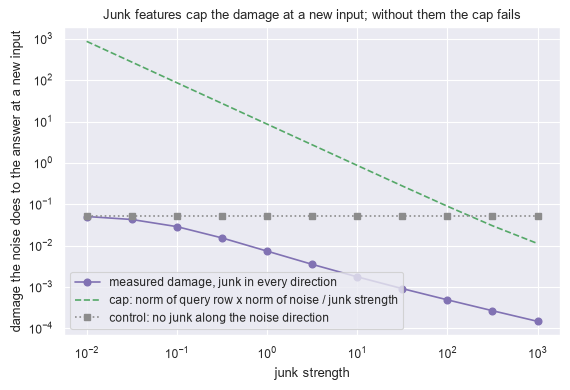

In [5]:
figure, axis = plt.subplots(figsize=(6.4, 4))
axis.loglog(tight_rows[:, 0], tight_rows[:, 1], "o-", color=MODEL, label="measured damage, junk in every direction")
axis.loglog(tight_rows[:, 0], tight_rows[:, 2], "--", color=BOUND, label="cap: norm of query row x norm of noise / junk strength")
axis.loglog(control_rows[:, 0], control_rows[:, 1], "s:", color=BEFORE, label="control: no junk along the noise direction")
axis.set_xlabel("junk strength")
axis.set_ylabel("damage the noise does to the answer at a new input")
axis.set_title("Junk features cap the damage at a new input; without them the cap fails")
axis.legend(loc="lower left")
save_figure(figure, "16-noise-damage-and-junk")
plt.show()

## Claim 4: pruning slows every direction, costs nothing where the dropped weights have no strength, and moves the fit farther (`Pruning`)

A 16-output problem with six kernel directions. The kept weights (30 of them) have strengths 2, 1, 0.5, 0.25, 0.1, 0.05
along them, and the dropped weights (30 more) have strengths 0.5, 0, 0.3, 0, 0.2, 0.1: two directions where the dropped weights
have no strength. The whole model is kept plus dropped, and its kernel is the sum. The learning rate is
`0.5 / (strongest whole strength)`, so `learning_rate * whole_strength <= 1`. Run real gradient descent for 60 steps on each
model, with the residual starting at the sum of the six directions, and read the share of the error left along each. The
theorem says: the whole model's share is `(1 - learning_rate * whole_strength) ** steps` and the pruned model's is
`(1 - learning_rate * kept_strength) ** steps`; the whole share is at most the pruned share; the two are equal where the
dropped strength is zero; and the pruned model's nearest fit, from a residual along one direction, is farther by
`sqrt((kept + dropped) / kept)`. **Prediction:** all of these to rounding. A result against the claim: a whole share above
the pruned one, or a travel ratio off by more than `1e-9`. The control breaks `learning_rate * whole_strength <= 1`: the rate
`1.9 / whole_strength` along the strongest direction, where the whole model's factor is `-0.9` and the pruned model's
`-0.52`; the whole share is then the larger in size.

In [6]:
generator = np.random.default_rng(SEED + 4)
NUM_PRUNE_DATA = 16
kept_strengths = np.array([2.0, 1.0, 0.5, 0.25, 0.1, 0.05])
dropped_strengths = np.array([0.5, 0.0, 0.3, 0.0, 0.2, 0.1])
whole_strengths = kept_strengths + dropped_strengths
directions = get_orthonormal_columns(generator, NUM_PRUNE_DATA, 6)
kept_rows = get_orthonormal_columns(generator, 30, 6)                                  # orthonormal 30 x 6
dropped_rows = get_orthonormal_columns(generator, 30, 6)
kept_features = directions @ np.diag(np.sqrt(kept_strengths)) @ kept_rows.T            # 16 x 30
dropped_features = directions @ np.diag(np.sqrt(dropped_strengths)) @ dropped_rows.T
whole_features = np.hstack([kept_features, dropped_features])                          # 16 x 60: the kernel is the sum
residual_start = directions.sum(axis=1)
NUM_PRUNE_STEPS = 60
learning_rate = 0.5 / whole_strengths.max()


def get_shares(features, labels, rate, num_steps):
    """Share of the starting error left along each direction, row t after t steps."""
    history = run_gradient_descent(features, labels, np.zeros(features.shape[1]), rate, num_steps)
    residuals = labels[None, :] - history @ features.T
    return residuals @ directions                                                      # starting error is 1 along each


steps = np.arange(NUM_PRUNE_STEPS + 1)
whole_share = get_shares(whole_features, residual_start, learning_rate, NUM_PRUNE_STEPS)
pruned_share = get_shares(kept_features, residual_start, learning_rate, NUM_PRUNE_STEPS)
formula_whole = (1 - learning_rate * whole_strengths) ** steps[:, None]
formula_pruned = (1 - learning_rate * kept_strengths) ** steps[:, None]
report("the real runs follow (1 - rate * strength) ** steps, for the whole and the pruned model",
       np.abs(whole_share - formula_whole).max() < 1e-9 and np.abs(pruned_share - formula_pruned).max() < 1e-9,
       f"largest gaps {np.abs(whole_share - formula_whole).max():.1e}, {np.abs(pruned_share - formula_pruned).max():.1e}")
note_by_construction("the whole model's share is at most the pruned model's, at every step and direction (follows from the formula checked above)",
       bool(np.all(whole_share <= pruned_share + 1e-12)),
       f"after 60 steps, along the strongest direction: whole {whole_share[-1, 0]:.3e}, pruned {pruned_share[-1, 0]:.3e}")
no_strength = dropped_strengths == 0
note_by_construction("winning ticket: where the dropped weights have no strength the two shares are equal (2 directions), and smaller elsewhere (follows from the formula)",
       bool(np.all(np.abs(whole_share[:, no_strength] - pruned_share[:, no_strength]) < 1e-12)) and int(no_strength.sum()) == 2
       and bool(np.all(whole_share[-1, ~no_strength] < pruned_share[-1, ~no_strength])))
travel_ratios = []
for index in range(6):
    along = directions[:, index]
    travel_whole = np.linalg.norm(np.linalg.pinv(whole_features) @ along)
    travel_pruned = np.linalg.norm(np.linalg.pinv(kept_features) @ along)
    travel_ratios.append((travel_pruned / travel_whole, np.sqrt(whole_strengths[index] / kept_strengths[index])))
travel_ratios = np.array(travel_ratios)
report("the nearest fit of the pruned model is farther by sqrt((kept + dropped) / kept), along each direction",
       np.abs(travel_ratios[:, 0] - travel_ratios[:, 1]).max() < 1e-9,
       f"measured ratios {np.round(travel_ratios[:, 0], 3)}")
big_rate = 1.9 / whole_strengths[0]
big_whole = get_shares(whole_features, residual_start, big_rate, 10)
big_pruned = get_shares(kept_features, residual_start, big_rate, 10)
report("control: with rate * whole_strength = 1.9 the whole model's share is larger in size than the pruned model's",
       abs(big_whole[1, 0]) > abs(big_pruned[1, 0]),
       f"after one step along the strongest direction: whole {big_whole[1, 0]:.2f}, pruned {big_pruned[1, 0]:.2f}")

[PASS] the real runs follow (1 - rate * strength) ** steps, for the whole and the pruned model  (largest gaps 5.6e-16, 5.6e-16)
[by construction, cannot fail] the whole model's share is at most the pruned model's, at every step and direction (follows from the formula checked above)  (after 60 steps, along the strongest direction: whole 1.234e-16, pruned 4.869e-14)
[by construction, cannot fail] winning ticket: where the dropped weights have no strength the two shares are equal (2 directions), and smaller elsewhere (follows from the formula)
[PASS] the nearest fit of the pruned model is farther by sqrt((kept + dropped) / kept), along each direction  (measured ratios [1.118 1.    1.265 1.    1.732 1.732])
[PASS] control: with rate * whole_strength = 1.9 the whole model's share is larger in size than the pruned model's  (after one step along the strongest direction: whole -0.90, pruned -0.52)


True

## Claim 5: a step on a new task moves the old errors through the cross kernel, by at most the new task's travel (`Forgetting`)

One set of 40 weights, two tasks: an old task of 12 points and a new task of 10, with random features. Weights start at the
old task's nearest fit, so the old errors start at zero. The theorem says: a gradient step on the new task changes the old
residual by `-learning_rate * old_features @ new_features.T @ new_residual`, exactly; if the cross kernel
`old_features @ new_features.T` is zero the old errors never change; and if gradient descent fits the new task the old
errors change by at most `norm(old_features) * travel`, the operator norm times the nearest-fit distance of the new task.
**Prediction:** the one-step formula to rounding, a change of exactly zero (below `1e-9`) in the zero-cross-kernel case, and a
measured change at most the ceiling in the general case. A result against the claim: a change above the ceiling. The
control is the general case itself: its cross kernel is not zero, and its old errors must move.

In [7]:
generator = np.random.default_rng(SEED + 5)
NUM_FORGET_WEIGHTS, NUM_OLD, NUM_NEW = 40, 12, 10
old_features = generator.standard_normal((NUM_OLD, NUM_FORGET_WEIGHTS)) / np.sqrt(NUM_FORGET_WEIGHTS)
new_features = generator.standard_normal((NUM_NEW, NUM_FORGET_WEIGHTS)) / np.sqrt(NUM_FORGET_WEIGHTS)
old_labels = generator.standard_normal(NUM_OLD)
new_labels = generator.standard_normal(NUM_NEW)
old_fit = np.linalg.pinv(old_features) @ old_labels
no_overlap_features = new_features - new_features @ np.linalg.pinv(old_features) @ old_features   # rows removed from the old rows' span


def measure_forgetting(old_features, new_features, learning_rate, start_weights, num_steps):
    """Old-error change after each step of gradient descent on the new task, and the new task's nearest-fit distance."""
    path = run_gradient_descent(new_features, new_labels, start_weights, learning_rate, num_steps)
    old_errors = old_labels[None, :] - path @ old_features.T
    changes = np.linalg.norm(old_errors - old_errors[0], axis=1)
    travel = np.linalg.norm(np.linalg.pinv(new_features) @ (new_labels - new_features @ start_weights))
    new_misfit = np.linalg.norm(new_labels - new_features @ path[-1])
    return changes, travel, new_misfit


# one step at random weights equals the cross-kernel formula
random_weights = generator.standard_normal(NUM_FORGET_WEIGHTS)
rate = 0.05
stepped = run_gradient_descent(new_features, new_labels, random_weights, rate, 1)[1]
old_change = (old_labels - old_features @ stepped) - (old_labels - old_features @ random_weights)
cross_formula = -rate * old_features @ new_features.T @ (new_labels - new_features @ random_weights)
report("one step on the new task changes the old errors by -rate * cross kernel @ new errors",
       np.abs(old_change - cross_formula).max() < 1e-12, f"largest gap {np.abs(old_change - cross_formula).max():.1e}")

rate = 0.5 / np.linalg.eigvalsh(new_features @ new_features.T).max()
NUM_FORGET_STEPS = 3000
changes, travel, misfit = measure_forgetting(old_features, new_features, rate, old_fit, NUM_FORGET_STEPS)
operator_norm = np.linalg.norm(old_features, 2)
ceiling = operator_norm * travel
print(f"general case: new task misfit {misfit:.1e} after {NUM_FORGET_STEPS} steps; old errors moved {changes[-1]:.3f}; "
      f"ceiling {ceiling:.3f} (norm {operator_norm:.3f} x travel {travel:.3f})")
report("the general case: the new task is fitted and the old errors moved by at most norm * travel",
       misfit < 1e-6 and changes.max() <= ceiling, f"largest change {changes.max():.3f} against ceiling {ceiling:.3f}")
report("control: with a nonzero cross kernel the old errors do move", changes[-1] > 0.1,
       f"cross kernel norm {np.linalg.norm(old_features @ new_features.T, 2):.3f}")

cross_zero = np.abs(old_features @ no_overlap_features.T).max()
changes_zero, travel_zero, misfit_zero = measure_forgetting(old_features, no_overlap_features, rate, old_fit, NUM_FORGET_STEPS)
report("zero cross kernel: the new task is fitted and the old errors never change",
       cross_zero < 1e-12 and misfit_zero < 1e-6 and changes_zero.max() < 1e-9,
       f"cross kernel entries at most {cross_zero:.1e}; new misfit {misfit_zero:.1e}; old errors moved at most {changes_zero.max():.1e}")

[PASS] one step on the new task changes the old errors by -rate * cross kernel @ new errors  (largest gap 3.5e-16)
general case: new task misfit 2.6e-16 after 3000 steps; old errors moved 2.983; ceiling 6.443 (norm 1.438 x travel 4.479)
[PASS] the general case: the new task is fitted and the old errors moved by at most norm * travel  (largest change 2.983 against ceiling 6.443)
[PASS] control: with a nonzero cross kernel the old errors do move  (cross kernel norm 1.046)
[PASS] zero cross kernel: the new task is fitted and the old errors never change  (cross kernel entries at most 5.1e-16; new misfit 5.2e-16; old errors moved at most 9.2e-15)


True

## Claim 6: a model can keep its loss on the data and be one small step from any label (`Dimple`)

An input is a position along a line (the data manifold) and a height off it. Real data has height zero. The model is
`profile(position) + slope * height` with `profile = sin`, whose slope limit is 1. Eight data points with random labels.
The theorem says: the loss on the data is the profile's, whatever `slope` is; the step `(label - profile) / slope` straight
off the manifold gives exactly the label; and the nearest distance from the data point `(position, 0, label)` to the model's
graph lies between `vertical_error / sqrt(1 + (1 + slope) ** 2)` and `vertical_error / slope`. The nearest distance is
found by Nelder-Mead from the best of a coarse grid of `(position, height)` around the data point (an even grid that
misses the dimple step itself, so the upper bound is not built in). **Prediction:** the three, for slopes 0.5, 2 and 8. A
result against the claim: a nearest distance outside the two bounds. The vertical error is reported next to every nearest
distance: the loss sees only that one. The control is `slope = 0`, which breaks `0 < slope`: no height changes the answer,
and the step cannot reach the label.

In [8]:
generator = np.random.default_rng(SEED + 6)
NUM_DIMPLE_POINTS = 8
positions = np.sort(generator.uniform(0, 2 * np.pi, NUM_DIMPLE_POINTS))
dimple_labels = generator.uniform(-2.0, 2.0, NUM_DIMPLE_POINTS)
PROFILE_SLOPE_LIMIT = 1.0


def evaluate_dimpled_model(position, height, slope):
    return np.sin(position) + slope * height


def get_nearest_distance_3d(position, label, slope, vertical_error):
    """Distance from (position, 0, label) to the graph of the dimpled model, over a window of size vertical_error."""
    def get_distance(point):
        return np.sqrt((point[0] - position) ** 2 + point[1] ** 2
                       + (evaluate_dimpled_model(point[0], point[1], slope) - label) ** 2)
    grid = np.linspace(-vertical_error, vertical_error, 120)                           # even count: height 0 is not a node
    grid_positions, grid_heights = np.meshgrid(position + grid, grid)
    values = np.sqrt((grid_positions - position) ** 2 + grid_heights ** 2
                     + (evaluate_dimpled_model(grid_positions, grid_heights, slope) - label) ** 2)
    best = np.unravel_index(np.argmin(values), values.shape)
    start = np.array([grid_positions[best], grid_heights[best]])
    result = minimize(get_distance, start, method="Nelder-Mead", options={"xatol": 1e-12, "fatol": 1e-14, "maxiter": 4000})
    return float(result.fun)


profile_loss = np.mean((dimple_labels - np.sin(positions)) ** 2)
losses = [np.mean((dimple_labels - evaluate_dimpled_model(positions, 0.0, slope)) ** 2) for slope in (0.5, 2.0, 8.0, 50.0)]
note_by_construction("on real data (height 0) the model is the profile, so the loss is the same for every slope", np.allclose(losses, profile_loss, atol=1e-14),
       f"loss {profile_loss:.4f} at slopes 0.5, 2, 8, 50")

print("slope: vertical error, nearest distance, [lower bound, upper bound]")
inside, step_error = [], 0.0
for slope in (0.5, 2.0, 8.0):
    for position, label in zip(positions, dimple_labels):
        vertical_error = abs(label - evaluate_dimpled_model(position, 0.0, slope))
        dimple_height = (label - np.sin(position)) / slope
        step_error = max(step_error, abs(evaluate_dimpled_model(position, dimple_height, slope) - label))
        nearest = get_nearest_distance_3d(position, label, slope, vertical_error)
        lower = vertical_error / np.sqrt(1 + (PROFILE_SLOPE_LIMIT + slope) ** 2)
        upper = vertical_error / slope
        inside.append((slope, vertical_error, nearest, lower, upper))
inside = np.array(inside)
for slope in (0.5, 2.0, 8.0):
    chosen = inside[inside[:, 0] == slope]
    print(f"  {slope:4}: vertical error {chosen[:, 1].mean():.3f}, nearest {chosen[:, 2].mean():.3f}, "
          f"bounds [{chosen[:, 3].mean():.3f}, {chosen[:, 4].mean():.3f}] (means over 8 points)")
note_by_construction("the step (label - profile) / slope straight off the manifold gives the label (algebra)", step_error < 1e-12,
       f"largest miss {step_error:.1e}")
report("the nearest distance lies between the two bounds, at 24 pairs of data point and slope",
       bool(np.all(inside[:, 2] >= inside[:, 3] - 1e-9)) and bool(np.all(inside[:, 2] <= inside[:, 4] + 1e-9)),
       f"nearest / upper bound between {np.min(inside[:, 2] / inside[:, 4]):.3f} and {np.max(inside[:, 2] / inside[:, 4]):.3f}")
report("at slope 8 the nearest distance is under a fifth of the vertical error",
       bool(np.all(inside[inside[:, 0] == 8.0][:, 2] < 0.2 * inside[inside[:, 0] == 8.0][:, 1])),
       f"nearest is at most {np.max(inside[inside[:, 0] == 8.0][:, 2] / inside[inside[:, 0] == 8.0][:, 1]):.3f} of the vertical error")
heights = np.linspace(-100, 100, 20001)
control_miss = np.abs(dimple_labels[:, None] - evaluate_dimpled_model(positions[:, None], heights[None, :], 0.0)).min(axis=1)
note_by_construction("control: with slope 0 no height off the manifold changes the answer, so no step reaches the label",
       np.allclose(control_miss, np.abs(dimple_labels - np.sin(positions)), atol=1e-12),
       f"closest approach to the label equals the vertical error, {control_miss.mean():.3f} on average")

[by construction, cannot fail] on real data (height 0) the model is the profile, so the loss is the same for every slope  (loss 1.5635 at slopes 0.5, 2, 8, 50)
slope: vertical error, nearest distance, [lower bound, upper bound]
   0.5: vertical error 0.990, nearest 0.705, bounds [0.549, 1.979] (means over 8 points)
   2.0: vertical error 0.990, nearest 0.413, bounds [0.313, 0.495] (means over 8 points)
   8.0: vertical error 0.990, nearest 0.122, bounds [0.109, 0.124] (means over 8 points)
[by construction, cannot fail] the step (label - profile) / slope straight off the manifold gives the label (algebra)  (largest miss 2.2e-16)
[PASS] the nearest distance lies between the two bounds, at 24 pairs of data point and slope  (nearest / upper bound between 0.338 and 0.992)
[PASS] at slope 8 the nearest distance is under a fifth of the vertical error  (nearest is at most 0.124 of the vertical error)
[by construction, cannot fail] control: with slope 0 no height off the manifold changes the a

## Claim 7: a model linear in `m` weights fits arbitrary labels on at most `m` points (`Capacity`)

`m = 50` weights, random features, random labels, 20 seeds, and `points` from 20 to 80. The theorem says: if a linear model can
fit every set of labels it has at least as many weights as points; so with 80 points and 50 weights, random labels
cannot be fitted. **Prediction:** the least-squares misfit is zero (below `1e-8`) for 20, 40, 50 points and positive (above
`1e-3`) for 51, 60, 80 points, in every seed. A result against the claim: a fit at 80 points. The control is a model with 50
weights of which only 30 are independent (the other 20 columns copy earlier ones): it fails already at 40 points, so
what counts is the dimension of the outputs the weights reach, not the weight count on paper.

In [9]:
generator = np.random.default_rng(SEED + 7)
NUM_CAPACITY_WEIGHTS = 50
point_counts = (20, 40, 50, 51, 60, 80)
worst_misfit, best_misfit = {}, {}
for points in point_counts:
    misfits = []
    for seed in range(20):
        features = generator.standard_normal((points, NUM_CAPACITY_WEIGHTS))
        random_labels = generator.standard_normal(points)
        weights = np.linalg.lstsq(features, random_labels, rcond=None)[0]
        misfits.append(np.linalg.norm(features @ weights - random_labels))
    worst_misfit[points], best_misfit[points] = max(misfits), min(misfits)
    print(f"{points} points, {NUM_CAPACITY_WEIGHTS} weights: misfit between {best_misfit[points]:.2e} and {worst_misfit[points]:.2e}")
report("up to 50 points random labels are fitted exactly, in all 20 seeds", all(worst_misfit[points] < 1e-8 for points in (20, 40, 50)))
report("from 51 points on they are not, in all 20 seeds (80 points included)", all(best_misfit[points] > 1e-3 for points in (51, 60, 80)),
       f"smallest misfit at 80 points {best_misfit[80]:.2f}")
copies = []
for seed in range(20):
    independent = generator.standard_normal((40, 30))
    features = np.hstack([independent, independent[:, :20]])                              # 50 weights, rank 30
    random_labels = generator.standard_normal(40)
    weights = np.linalg.lstsq(features, random_labels, rcond=None)[0]
    copies.append(np.linalg.norm(features @ weights - random_labels))
report("control: 50 weights of rank 30 fail at 40 points, in all 20 seeds", min(copies) > 1e-3,
       f"smallest misfit {min(copies):.2f}")

20 points, 50 weights: misfit between 4.39e-15 and 1.50e-14
40 points, 50 weights: misfit between 8.00e-15 and 3.40e-14
50 points, 50 weights: misfit between 1.36e-14 and 1.79e-12
51 points, 50 weights: misfit between 7.68e-03 and 1.77e+00
60 points, 50 weights: misfit between 2.03e+00 and 4.23e+00
80 points, 50 weights: misfit between 4.79e+00 and 5.97e+00
[PASS] up to 50 points random labels are fitted exactly, in all 20 seeds
[PASS] from 51 points on they are not, in all 20 seeds (80 points included)  (smallest misfit at 80 points 4.79)
[PASS] control: 50 weights of rank 30 fail at 40 points, in all 20 seeds  (smallest misfit 2.28)


True

## Claim 8: with no pattern in the labels, a guess at an unseen input is right on half of all labellings (`Perceptron`)

Eight inputs on a line, positions 0 to 7. The learner sees the labels at inputs 0, 2, 3, 5, 7 and must guess the labels at 1,
4 and 6. All 256 labellings of the eight inputs are tried. Four learners: always `+1`; the majority of the training labels;
the nearest training input's label; and the sign of a least-squares line through the training labels. The theorem says:
for a fixed unseen input and a fixed guess, exactly half the labellings agree; and a prediction `p` against a label that is
`+1` or `-1` with equal chance has mean squared error `p ** 2 + 1`. **Prediction:** each learner's accuracy on the unseen
inputs, averaged over all 256 labellings, is exactly 0.5, however clever it is. A result against the claim: any learner off
0.5. The control removes the "no pattern": only the nine step labellings (all `-1` up to some input, all `+1` after) are
tried, and the nearest-input learner must then beat 0.5, the size of its edge reported.

In [10]:
import itertools

NUM_LINE = 8
TRAIN = [0, 2, 3, 5, 7]
UNSEEN = [1, 4, 6]
all_labellings = np.array(list(itertools.product([-1, 1], repeat=NUM_LINE)))             # 256 x 8


def guess_plus(train_labels):
    return {unseen: 1 for unseen in UNSEEN}


def guess_majority(train_labels):
    vote = 1 if train_labels.sum() >= 0 else -1
    return {unseen: vote for unseen in UNSEEN}


def guess_nearest(train_labels):
    guesses = {}
    for unseen in UNSEEN:
        closest = min(range(len(TRAIN)), key=lambda index: (abs(TRAIN[index] - unseen), TRAIN[index]))
        guesses[unseen] = int(train_labels[closest])
    return guesses


def guess_line(train_labels):
    design = np.stack([np.ones(len(TRAIN)), np.array(TRAIN, dtype=float)], axis=1)
    intercept, slope = np.linalg.lstsq(design, train_labels.astype(float), rcond=None)[0]
    return {unseen: 1 if intercept + slope * unseen >= 0 else -1 for unseen in UNSEEN}


def measure_accuracy(learner, labellings):
    agree = 0
    for labelling in labellings:
        guesses = learner(labelling[TRAIN])
        agree += sum(guesses[unseen] == labelling[unseen] for unseen in UNSEEN)
    return agree / (len(labellings) * len(UNSEEN))


learners = {"always plus": guess_plus, "majority": guess_majority, "nearest input": guess_nearest, "least-squares line": guess_line}
accuracies = {name: measure_accuracy(learner, all_labellings) for name, learner in learners.items()}
for name, accuracy in accuracies.items():
    print(f"{name}: accuracy on the unseen inputs over all {len(all_labellings)} labellings {accuracy:.4f}")
note_by_construction("every learner is right on exactly half of all labellings at the unseen inputs (a counting identity)",
       all(accuracy == 0.5 for accuracy in accuracies.values()))
for guess in (-1, 1):
    for unseen in UNSEEN:
        assert np.sum(all_labellings[:, unseen] == guess) == np.sum(all_labellings[:, unseen] != guess)
predictions = (-2.0, -0.5, 0.0, 0.3, 1.7)
errors = [np.mean([(prediction - label) ** 2 for label in (-1, 1)]) for prediction in predictions]
note_by_construction("for a fixed guess, as many labellings agree as disagree; mean squared error is p ** 2 + 1 (counting and algebra)",
       np.allclose(errors, [prediction ** 2 + 1 for prediction in predictions]), f"errors {np.round(errors, 3)}")
step_labellings = np.array([[-1] * cut + [1] * (NUM_LINE - cut) for cut in range(NUM_LINE + 1)])
edge = measure_accuracy(guess_nearest, step_labellings) - 0.5
report("control: on step labellings (a pattern) the nearest-input learner beats 0.5", edge > 0.1,
       f"accuracy {0.5 + edge:.3f} over the nine step labellings")

always plus: accuracy on the unseen inputs over all 256 labellings 0.5000
majority: accuracy on the unseen inputs over all 256 labellings 0.5000
nearest input: accuracy on the unseen inputs over all 256 labellings 0.5000
least-squares line: accuracy on the unseen inputs over all 256 labellings 0.5000
[by construction, cannot fail] every learner is right on exactly half of all labellings at the unseen inputs (a counting identity)
[by construction, cannot fail] for a fixed guess, as many labellings agree as disagree; mean squared error is p ** 2 + 1 (counting and algebra)  (errors [5.   1.25 1.   1.09 3.89])
[PASS] control: on step labellings (a pattern) the nearest-input learner beats 0.5  (accuracy 0.889 over the nine step labellings)


True